# Cookie Cats — A/B Test: Gate at Level 30 vs Level 40

## 1. Goal

**Cookie Cats** is a mobile puzzle game by Tactile Entertainment. As players
progress through the levels they hit *gates*: they must wait a while, or make
an in-app purchase, before they can continue. Gates give players a break and
are also a point where the game earns money.

The first gate was originally at **level 30**. The test asks: **what happens
to player engagement and retention if the first gate is moved to level 40?**
New players were randomly assigned at install to one of two versions:

- `gate_30` — control, gate at level 30
- `gate_40` — treatment, gate at level 40

The goal is to decide whether the game should move the gate to level 40 or
keep it at level 30.

**Columns**
- `userid` – unique player id
- `version` – experiment group (`gate_30` / `gate_40`)
- `sum_gamerounds` – game rounds played in the first 14 days after install
- `retention_1` – did the player come back 1 day after installing?
- `retention_7` – did the player come back 7 days after installing?

## 2. Target metric

**Primary metric: 7-day retention** — the share of players who open the game
again 7 days after installing it.

- A free-to-play game makes money only from players who keep playing, so
  long-term retention is the best available measure of the game's health.
  7-day retention captures whether players are still engaged after the
  novelty wears off.
- Most players reach level 30–40 after a few days, so the gate change can
  only plausibly affect retention later on. **1-day retention** is measured
  too early for most players to have reached either gate.
- It is a simple yes/no outcome per player, so it is easy to interpret and
  test.

**Secondary metrics:** 1-day retention and the number of game rounds played
in the first 14 days. These are reported to give a fuller picture but do not
drive the decision.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, proportion_confint

pd.set_option("display.float_format", "{:.4f}".format)
plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

# Fixed colour per group, used consistently in every chart
COLORS = {"gate_30": "#2a78d6", "gate_40": "#eb6834"}
GROUPS = ["gate_30", "gate_40"]
ALPHA = 0.05
rng = np.random.default_rng(42)

## 3. Calculations

### 3.1 Load and sanity-check the data

In [2]:
df = pd.read_csv("cookie_cats.csv")
print(df.shape)
df.head()

(90189, 5)


,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


In [3]:
df.info()
print("\nMissing values:\n", df.isna().sum())
print("\nDuplicate user ids:", df["userid"].duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 90189 entries, 0 to 90188
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   userid          90189 non-null  int64
 1   version         90189 non-null  str  
 2   sum_gamerounds  90189 non-null  int64
 3   retention_1     90189 non-null  bool 
 4   retention_7     90189 non-null  bool 
dtypes: bool(2), int64(2), str(1)
memory usage: 2.2 MB

Missing values:
 userid            0
version           0
sum_gamerounds    0
retention_1       0
retention_7       0
dtype: int64

Duplicate user ids: 0


### 3.2 Sample size, variant proportions and sample ratio mismatch (SRM)
Players should have been split 50/50. A chi-square goodness-of-fit test checks whether the
observed split is consistent with that — if not, the randomisation itself may be broken.

In [4]:
counts = df["version"].value_counts().reindex(GROUPS)
chi2, p_srm = stats.chisquare(counts)
print(counts)
print(f"\nSplit: {counts.iloc[0] / counts.sum():.2%} / {counts.iloc[1] / counts.sum():.2%}")
print(f"SRM chi-square = {chi2:.2f}, p = {p_srm:.4f}")

version
gate_30    44700
gate_40    45489
Name: count, dtype: int64

Split: 49.56% / 50.44%
SRM chi-square = 6.90, p = 0.0086


The split is 49.56% / 50.44% and the SRM test **is significant (p ≈ 0.009)**: `gate_40` has ~790 more
players than a true 50/50 split would give. The imbalance is small (<1 pp) and both groups look
alike on every other measure (rounds distribution, share of zero-round players). So we continue, but
this is a **real caveat**: an SRM can point to a bug in assignment or logging that also biases the
metrics. In a production setting you would investigate it before trusting the result.

### 3.3 Outliers in `sum_gamerounds`

In [5]:
df["sum_gamerounds"].describe(percentiles=[.25, .5, .75, .9, .99, .999])

count   90189.0000
mean       51.8725
std       195.0509
min         0.0000
25%         5.0000
50%        16.0000
75%        51.0000
90%       134.0000
99%       493.0000
99.9%    1073.6240
max     49854.0000
Name: sum_gamerounds, dtype: float64

In [6]:
df.nlargest(5, "sum_gamerounds")

,userid,version,sum_gamerounds,retention_1,retention_7
57702,6390605,gate_30,49854,False,True
7912,871500,gate_30,2961,True,True
29417,3271615,gate_40,2640,True,False
43671,4832608,gate_30,2438,True,True
48188,5346171,gate_40,2294,True,True


One `gate_30` player logged **49,854 rounds** in 14 days — about 17× the next-highest player and
~3,500 rounds per day. That is almost certainly a logging error or a bot, so we drop it.

In [7]:
df = df[df["sum_gamerounds"] < df["sum_gamerounds"].max()].copy()
print(df.shape)
df.groupby("version")["sum_gamerounds"].describe()

(90188, 5)


,count,mean,std,min,25%,50%,75%,max
version,,,,,,,,
gate_30,44699.0000,51.3421,102.0576,0.0000,5.0000,17.0000,50.0000,2961.0000
gate_40,45489.0000,51.2988,103.2944,0.0000,5.0000,16.0000,52.0000,2640.0000


In [8]:
zero = (df["sum_gamerounds"] == 0).groupby(df["version"]).agg(["sum", "mean"])
zero.columns = ["players_with_0_rounds", "share"]
zero

,players_with_0_rounds,share
version,,
gate_30,1937,0.0433
gate_40,2057,0.0452


Around 4–5% of players installed the game but never played a round. They are kept: they are real
users who were assigned to a group, and excluding them would bias the retention estimates upward.

### 3.4 Exploratory analysis

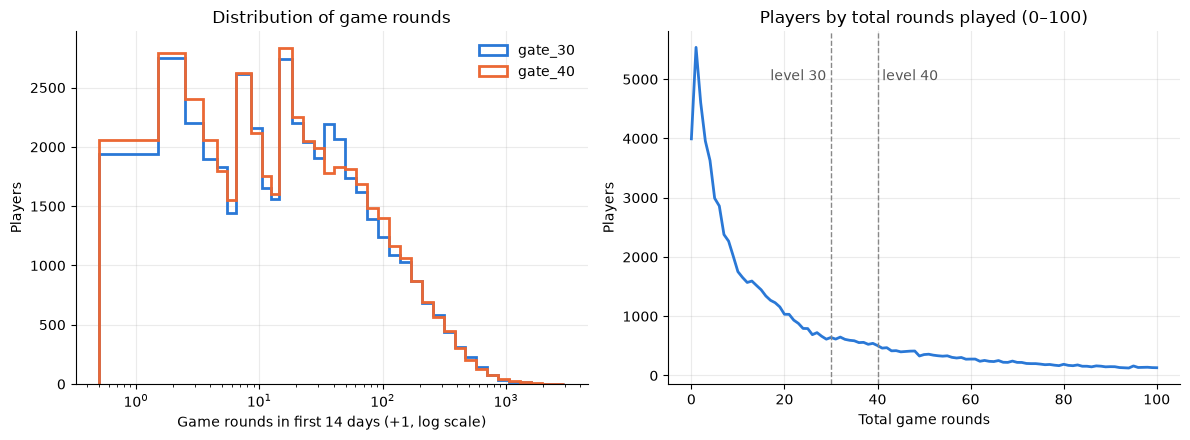

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Left: distribution of rounds (log x-axis — the data is very right-skewed)
# Bin edges sit halfway between integers so every round count lands cleanly in one bin
edges = np.unique(np.round(np.logspace(0, np.log10(df["sum_gamerounds"].max() + 2), 40)))
bins = np.concatenate([[0.5], edges + 0.5])
for g in GROUPS:
    axes[0].hist(df.loc[df["version"] == g, "sum_gamerounds"] + 1, bins=bins,
                 histtype="step", linewidth=2, color=COLORS[g], label=g)
axes[0].set_xscale("log")
axes[0].set_xlabel("Game rounds in first 14 days (+1, log scale)")
axes[0].set_ylabel("Players")
axes[0].set_title("Distribution of game rounds")
axes[0].legend(frameon=False)

# Right: how many players are still around at each round count (first 100 rounds)
rounds = df.groupby("sum_gamerounds")["userid"].count().loc[:100]
axes[1].plot(rounds.index, rounds.values, color="#2a78d6", linewidth=2)
for lvl, ha, dx in ((30, "right", -1), (40, "left", 1)):
    axes[1].axvline(lvl, color="#888", linestyle="--", linewidth=1)
    axes[1].text(lvl + dx, rounds.max() * 0.9, f"level {lvl}", color="#555", ha=ha)
axes[1].set_xlabel("Total game rounds")
axes[1].set_ylabel("Players")
axes[1].set_title("Players by total rounds played (0–100)")

plt.tight_layout()
plt.show()

Most players churn very early: the median player plays only ~16 rounds, so many never reach level 30
at all — for them the gate position cannot matter. This dilutes any treatment effect.

In [10]:
summary = df.groupby("version").agg(
    players=("userid", "count"),
    median_rounds=("sum_gamerounds", "median"),
    mean_rounds=("sum_gamerounds", "mean"),
    retention_1=("retention_1", "mean"),
    retention_7=("retention_7", "mean"),
)
summary

,players,median_rounds,mean_rounds,retention_1,retention_7
version,,,,,
gate_30,44699,17.0000,51.3421,0.4482,0.1902
gate_40,45489,16.0000,51.2988,0.4423,0.1820


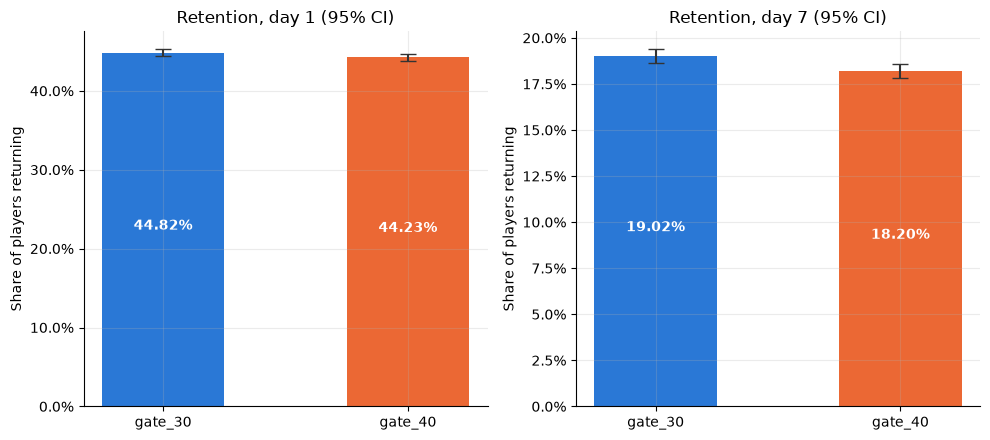

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharey=False)
for ax, metric in zip(axes, ["retention_1", "retention_7"]):
    rates, lo, hi = [], [], []
    for g in GROUPS:
        s = df.loc[df["version"] == g, metric]
        l, h = proportion_confint(s.sum(), len(s), alpha=ALPHA, method="wilson")
        rates.append(s.mean()); lo.append(s.mean() - l); hi.append(h - s.mean())
    ax.bar(GROUPS, rates, color=[COLORS[g] for g in GROUPS], width=0.5,
           yerr=[lo, hi], capsize=6, error_kw={"elinewidth": 1.5, "ecolor": "#333"})
    for i, r in enumerate(rates):
        ax.text(i, r / 2, f"{r:.2%}", ha="center", color="white", fontweight="bold")
    ax.set_title(metric.replace("_", " ").replace("retention", "Retention, day") + " (95% CI)")
    ax.set_ylabel("Share of players returning")
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
plt.tight_layout()
plt.show()

### 3.5 Statistical tests

For each metric:

- **H₀**: no difference between `gate_30` and `gate_40`
- **H₁**: there is a difference (two-sided), significance level α = 0.05

#### Retention — two-proportion z-test
Retention is a yes/no outcome per player, so each group's retention rate is
a **proportion** and we compare two proportions. The two-proportion z-test
does exactly that. It gives the same p-value as a chi-square test on the 2×2
table (group × retained), because for two groups z² = χ². A t-test is not
needed: with ~45,000 players per group the normal approximation to the
binomial distribution is extremely accurate.

In [12]:
def retention_test(metric):
    a = df.loc[df["version"] == "gate_30", metric]
    b = df.loc[df["version"] == "gate_40", metric]
    z, p = proportions_ztest([a.sum(), b.sum()], [len(a), len(b)])
    diff = a.mean() - b.mean()
    se = np.sqrt(a.mean() * (1 - a.mean()) / len(a) + b.mean() * (1 - b.mean()) / len(b))
    zcrit = stats.norm.ppf(1 - ALPHA / 2)
    return {
        "metric": metric,
        "gate_30": a.mean(),
        "gate_40": b.mean(),
        "diff (30 - 40)": diff,
        "95% CI low": diff - zcrit * se,
        "95% CI high": diff + zcrit * se,
        "relative lift of gate_30": diff / b.mean(),
        "z": z,
        "p_value": p,
        "significant": p < ALPHA,
    }

ret_results = pd.DataFrame([retention_test(m) for m in ["retention_1", "retention_7"]]).set_index("metric")
ret_results.T

metric,retention_1,retention_7
gate_30,0.4482,0.1902
gate_40,0.4423,0.1820
diff (30 - 40),0.0059,0.0082
95% CI low,-0.0006,0.0031
95% CI high,0.0124,0.0133
relative lift of gate_30,0.0134,0.0450
z,1.7871,3.1574
p_value,0.0739,0.0016
significant,False,True


#### Engagement — Mann–Whitney U test on game rounds
`sum_gamerounds` is extremely skewed with a long tail, so a t-test on means is not appropriate.
Mann–Whitney U is a non-parametric test asking whether a random `gate_30` player tends to play
more (or fewer) rounds than a random `gate_40` player.

In [13]:
a = df.loc[df["version"] == "gate_30", "sum_gamerounds"]
b = df.loc[df["version"] == "gate_40", "sum_gamerounds"]
u, p_mw = stats.mannwhitneyu(a, b, alternative="two-sided")
# Common-language effect size: P(random gate_30 player > random gate_40 player)
cles = u / (len(a) * len(b))
print(f"Median rounds  gate_30 = {a.median():.0f}, gate_40 = {b.median():.0f}")
print(f"Mann-Whitney U = {u:,.0f}, p = {p_mw:.4f}")
print(f"P(gate_30 player plays more than gate_40 player) = {cles:.4f}")

Median rounds  gate_30 = 17, gate_40 = 16
Mann-Whitney U = 1,024,285,762, p = 0.0509
P(gate_30 player plays more than gate_40 player) = 0.5038


### 3.6 Confidence interval: analytic vs bootstrap

The z-test above gives an **analytic** confidence interval: it uses a formula
that assumes the difference in proportions is approximately normally
distributed. The **bootstrap** makes no such assumption: it resamples
players with replacement many times, recomputes each group's retention rate,
and reads the interval straight off the distribution of the differences. It
also gives a direct estimate of **P(gate_30 has higher retention than
gate_40)**.

In [14]:
N_BOOT = 2000
groups = {g: df.loc[df["version"] == g, ["retention_1", "retention_7"]].to_numpy() for g in GROUPS}

boot = {"retention_1": [], "retention_7": []}
for _ in range(N_BOOT):
    means = {}
    for g, arr in groups.items():
        idx = rng.integers(0, len(arr), len(arr))
        means[g] = arr[idx].mean(axis=0)
    diff = means["gate_30"] - means["gate_40"]
    boot["retention_1"].append(diff[0])
    boot["retention_7"].append(diff[1])
boot = pd.DataFrame(boot)

boot_summary = pd.DataFrame({
    "mean diff (30 - 40)": boot.mean(),
    "2.5%": boot.quantile(0.025),
    "97.5%": boot.quantile(0.975),
    "P(gate_30 > gate_40)": (boot > 0).mean(),
})
boot_summary

,mean diff (30 - 40),2.5%,97.5%,P(gate_30 > gate_40)
retention_1,0.0059,-0.0004,0.0125,0.9650
retention_7,0.0083,0.0033,0.0135,0.9990


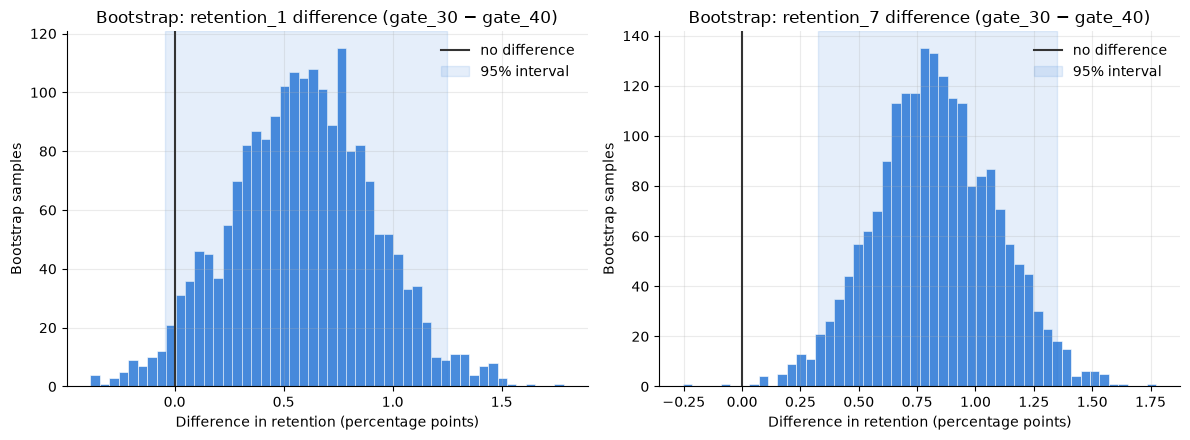

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, metric in zip(axes, ["retention_1", "retention_7"]):
    d = boot[metric] * 100
    lo, hi = np.percentile(d, [2.5, 97.5])
    ax.hist(d, bins=50, color="#2a78d6", alpha=0.85, edgecolor="white", linewidth=0.5)
    ax.axvline(0, color="#333", linewidth=1.5, label="no difference")
    ax.axvspan(lo, hi, color="#2a78d6", alpha=0.12, label="95% interval")
    ax.set_title(f"Bootstrap: {metric} difference (gate_30 − gate_40)")
    ax.set_xlabel("Difference in retention (percentage points)")
    ax.set_ylabel("Bootstrap samples")
    ax.legend(frameon=False)
plt.tight_layout()
plt.show()

Comparing the two 95% confidence intervals for the difference
(`gate_30` − `gate_40`, in percentage points):

In [16]:
ci_compare = pd.DataFrame({
    "estimate": ret_results["diff (30 - 40)"],
    "analytic_low": ret_results["95% CI low"],
    "analytic_high": ret_results["95% CI high"],
    "bootstrap_low": boot_summary["2.5%"],
    "bootstrap_high": boot_summary["97.5%"],
}) * 100
ci_compare.round(2)

,estimate,analytic_low,analytic_high,bootstrap_low,bootstrap_high
retention_1,0.5900,-0.0600,1.2400,-0.0400,1.2500
retention_7,0.8200,0.3100,1.3300,0.3300,1.3500


The two methods agree to within a few hundredths of a percentage point. That
is expected: with ~45,000 players per group, the normal approximation behind
the analytic formula is very accurate. The agreement means the conclusions
do not depend on that assumption.

**Where does the uncertainty come from?** Each player either returns or not,
and which players happened to land in each group is random. If the test were
rerun with a fresh set of players, the observed retention rates would differ
slightly. The confidence interval shows the range of true differences that
are consistent with what we observed.

## 4. Decision

### 4.1 Treatment effect with confidence intervals

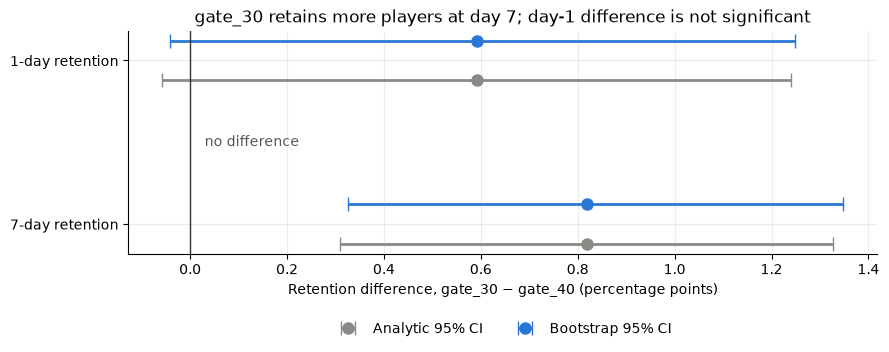

In [17]:
labels = {"retention_1": "1-day retention", "retention_7": "7-day retention"}
fig, ax = plt.subplots(figsize=(9, 3.8))
y = np.arange(len(ci_compare))
for shift, method, color in [(0.12, "analytic", "#8a8985"),
                             (-0.12, "bootstrap", "#2a78d6")]:
    low, high = ci_compare[f"{method}_low"], ci_compare[f"{method}_high"]
    est = ci_compare["estimate"]
    ax.errorbar(est, y + shift, xerr=[est - low, high - est], fmt="o", ms=8,
                color=color, capsize=5, elinewidth=2,
                label=f"{method.capitalize()} 95% CI")
ax.axvline(0, color="#333", linewidth=1)
ax.text(0.03, 0.5, "no difference", color="#555", va="center")
ax.set_yticks(y, [labels[m] for m in ci_compare.index])
ax.invert_yaxis()
ax.set_xlabel("Retention difference, gate_30 − gate_40 (percentage points)")
ax.set_title("gate_30 retains more players at day 7; "
             "day-1 difference is not significant")
ax.legend(frameon=False, loc="upper center", ncols=2,
          bbox_to_anchor=(0.5, -0.25))
plt.tight_layout()
plt.show()

### 4.2 Results summary

In [18]:
report = pd.DataFrame({
    "gate_30": [summary.loc["gate_30", "retention_1"], summary.loc["gate_30", "retention_7"], a.median()],
    "gate_40": [summary.loc["gate_40", "retention_1"], summary.loc["gate_40", "retention_7"], b.median()],
    "p_value": [ret_results.loc["retention_1", "p_value"], ret_results.loc["retention_7", "p_value"], p_mw],
    "P(gate_30 better), bootstrap": [boot_summary.loc["retention_1", "P(gate_30 > gate_40)"],
                                     boot_summary.loc["retention_7", "P(gate_30 > gate_40)"], np.nan],
}, index=["1-day retention", "7-day retention", "median game rounds"])
report["significant (α=0.05)"] = report["p_value"] < ALPHA
report

,gate_30,gate_40,p_value,"P(gate_30 better), bootstrap",significant (α=0.05)
1-day retention,0.4482,0.4423,0.0739,0.9650,False
7-day retention,0.1902,0.1820,0.0016,0.9990,True
median game rounds,17.0000,16.0000,0.0509,NaN,False


### 4.3 Recommendation

- **7-day retention is the key result.** `gate_30` retains about **19.0%** of players at day 7 vs
  **18.2%** for `gate_40`, a gap of roughly 0.8 percentage points (~4.5% relative). The z-test is
  significant (p ≈ 0.002, 95% CI 0.3–1.3 pp), and the bootstrap puts the probability that `gate_30` is better at ~99.9%.
- **1-day retention** is also slightly higher for `gate_30` (44.8% vs 44.2%), but the difference
  is **not statistically significant** (p ≈ 0.07) — unsurprising, since most players haven't reached level 30
  within a day.
- **Game rounds**: medians are 17 (`gate_30`) vs 16 (`gate_40`). The Mann–Whitney test is borderline
  (p ≈ 0.051, not significant), and the effect size is negligible: a random `gate_30` player
  out-plays a random `gate_40` player only 50.4% of the time.

**Recommendation: keep the gate at level 30.** Moving it to level 40 does not improve retention and
appears to slightly reduce 7-day retention. A plausible explanation is *hedonic adaptation* — the
earlier break stops players burning out on the game, so they are more likely to return.

**Limitations**
- Retention is a proxy. There is no revenue / in-app-purchase data, and the gate is also a
  monetisation point, so the business impact is not fully measured.
- Many players never reach level 30, which dilutes the effect. A follow-up analysis restricted to
  players who reached level 30 would isolate it better — but that subset is selected *after*
  treatment, so it must be interpreted with care.
- The sample-ratio check failed (p ≈ 0.009, Section 3.2). The imbalance is small, but the cause should be
  understood before treating the result as final.

### 4.4 Dashboard

The key results of this test (and of the Fast Food marketing test) are summarised in an
interactive dashboard: **[A/B Test Results dashboard](https://claude.ai/artifact/SaBVAPZSgGkDjRTq28K2DB)**.